# Análise e Comparação de Curvas de Juros: Cython vs B3
Neste notebook construímos as curvas Onshore (DIxPRE, SELICxPRE, TBFxPRE, TRxPRE) usando o Motor Cython. Extrairemos o Vértice 1 diretamente do Banco Central (SGS) e compararemos a curva final gerada com a curva oficial divulgada pela B3. Também validaremos o algoritmo de Suavização via Spline.

In [15]:
import os
import datetime
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from bcb import sgs

from bz_pricing.curves.builder import B3CurveBuilder
from bz_pricing.data.loaders import B3DataLoader
from bz_pricing.data.scrapers import B3Scraper
from bz_pricing.curves.tbf_pipeline import build_tbf_pipeline

plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (14, 7)

In [16]:
from importlib import metadata
from pandas.tseries.offsets import BDay
# Configuração Base
base_date = datetime.date(2026, 9, 4)
data_dir = os.path.join("../dados/b3")
loader = B3DataLoader(data_dir)
builder = B3CurveBuilder()
scraper = B3Scraper(output_dir=data_dir)

# Baixa os 5 dias úteis anteriores caso não existam (necessário para TBF)
for i in range(1, 6):
    d = (pd.to_datetime(base_date) - BDay(i)).date()
    date_str = d.strftime('%Y%m%d')
    if not os.path.exists(os.path.join(data_dir, f'BVBG_SPRD_{date_str}.csv')):
        print(f'Baixando TBF histórico: {date_str}')
        scraper.download_bvbg_187_01(d)


Baixando TBF histórico: 20260903
Baixando: https://www.b3.com.br/pesquisapregao/download?filelist=SPRD260903.zip
Lendo XML interno: BVBG.187.01_BV000471202609030001000072031250220.xml
Lendo XML interno: BVBG.187.01_BV000471202609030001000071928259590.xml
CSV salvo em: ../dados/b3\BVBG_SPRD_20260903.csv
Baixando TBF histórico: 20260902
Baixando: https://www.b3.com.br/pesquisapregao/download?filelist=SPRD260902.zip
Lendo XML interno: BVBG.187.01_BV000471202609020001000072033046640.xml
Lendo XML interno: BVBG.187.01_BV000471202609020001000071926366300.xml
CSV salvo em: ../dados/b3\BVBG_SPRD_20260902.csv
Baixando TBF histórico: 20260901
Baixando: https://www.b3.com.br/pesquisapregao/download?filelist=SPRD260901.zip
Lendo XML interno: BVBG.187.01_BV000471202609010001000072031281420.xml
Lendo XML interno: BVBG.187.01_BV000471202609010001000071920287080.xml
CSV salvo em: ../dados/b3\BVBG_SPRD_20260901.csv
Baixando TBF histórico: 20260831
Baixando: https://www.b3.com.br/pesquisapregao/download

## 1. Extração do Vértice 1 (BCB SGS)

In [17]:
# CDI (Série 12) e Selic (Série 4389)
df_bcb = sgs.get({'CDI': 12, 'SELIC': 4389}, start=base_date, end=base_date)
if not df_bcb.empty:
    v1_cdi = df_bcb['CDI'].iloc[0] / 100.0
    v1_selic = df_bcb['SELIC'].iloc[0] / 100.0
    v1_cdi = round((1+v1_cdi)**252-1,5)
    #v1_selic = round((1+v1_selic)**252-1,5)
else:
    # Fallback caso a API do BCB falhe para a data futura
    v1_cdi = 0.1040
    v1_selic = 0.1050
print(f"Vértice 1 CDI: {v1_cdi*100:.2f}%")
print(f"Vértice 1 SELIC: {v1_selic*100:.2f}%")

Vértice 1 CDI: 13.90%
Vértice 1 SELIC: 13.90%


## 2. Construindo a Curva PRE (DI x PRE) com e sem Suavização

In [18]:
# Extrai contratos DI1
df_di1 = loader.get_curve_instruments(base_date, asst="DI1")

# Constrói a curva Padrão B3 (Exponential Interpolator)
curve_pre_std = builder.build_from_config(df_di1, "PRE", base_date, v1_rate=v1_cdi)

# Constrói a curva com Suavização Spline
curve_pre_smooth = builder.build_from_config(df_di1, "PRE", base_date, v1_rate=v1_cdi, smoothing=0.0001)

# Baixa a curva oficial da B3 para comparação
b3_pre_path = scraper.download_taxas_referenciais(data = base_date, produto = "PRE")

# Le os dados baixados
df_b3_pre = pd.read_csv(b3_pre_path, sep = ';')

Baixando Taxas Referenciais (PRE) via API...


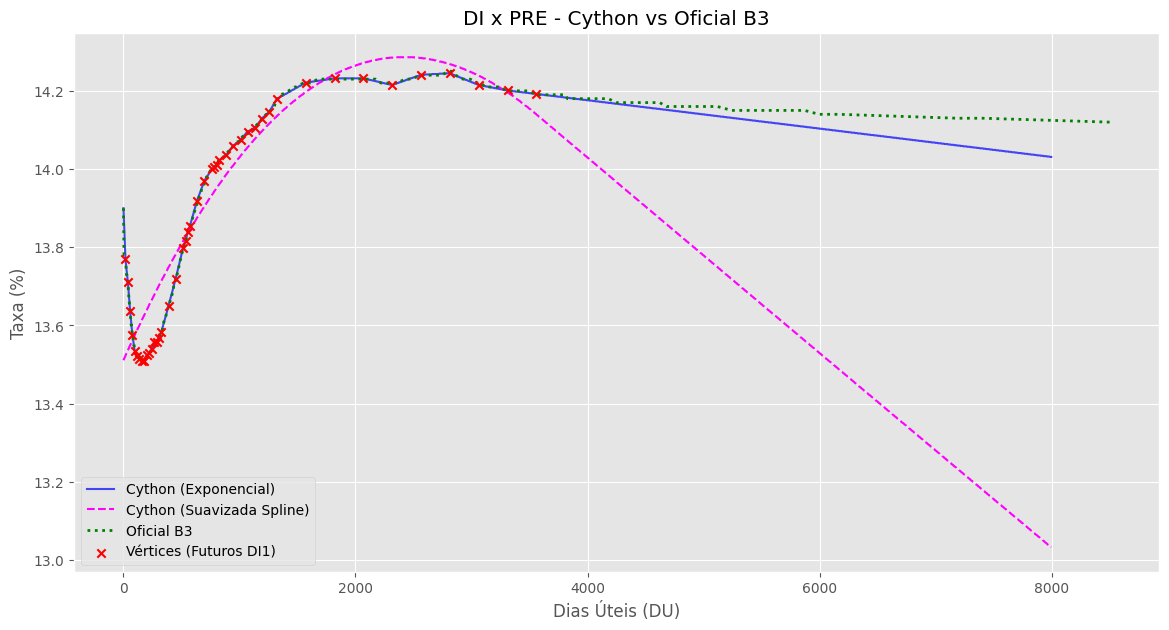

In [19]:
du_grid = np.arange(1, 8000, 5)
rates_std = [curve_pre_std.get_rate(float(du)) * 100 for du in du_grid]
rates_smooth = [curve_pre_smooth.get_rate(float(du)) * 100 for du in du_grid]

plt.plot(du_grid, rates_std, label='Cython (Exponencial)', color='blue', alpha=0.7)
plt.plot(du_grid, rates_smooth, label='Cython (Suavizada Spline)', color='magenta', linestyle='--')

if df_b3_pre is not None and not df_b3_pre.empty:
    plt.plot(df_b3_pre['day252'], df_b3_pre['rate'], label='Oficial B3', color='green', linewidth=2, linestyle=':')

# Pontos dos Contratos Futuros Originais
cal = builder.cal
df_di1['DU'] = [cal.bizdays(base_date, pd.to_datetime(d).date()) for d in df_di1['XprtnDt']]
df_di1_valid = df_di1[df_di1['DU'] > 0]
plt.scatter(df_di1_valid['DU'], df_di1_valid['AdjstdQtTax'], color='red', marker='x', label='Vértices (Futuros DI1)', zorder=5)

plt.title(f'DI x PRE - Cython vs Oficial B3')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (%)')
plt.legend()
plt.show()

## 3. Construindo a Curva SELIC x PRE

In [20]:
# OC1 Contracts (Liquidity Filter is now OFF in configs.py so we see the full curve)
df_oc1 = loader.get_curve_instruments(base_date, asst="OC1")

curve_selic = builder.build_from_config(df_oc1, "SELIC_PRE", base_date, v1_rate=v1_selic)

# Taxas Referenciais da B3
b3_selic_path = scraper.download_taxas_referenciais(data=base_date, produto="SLP")

# Le os dados baixados
df_b3_selic = pd.read_csv(b3_selic_path, sep = ';')

Baixando Taxas Referenciais (SLP) via API...


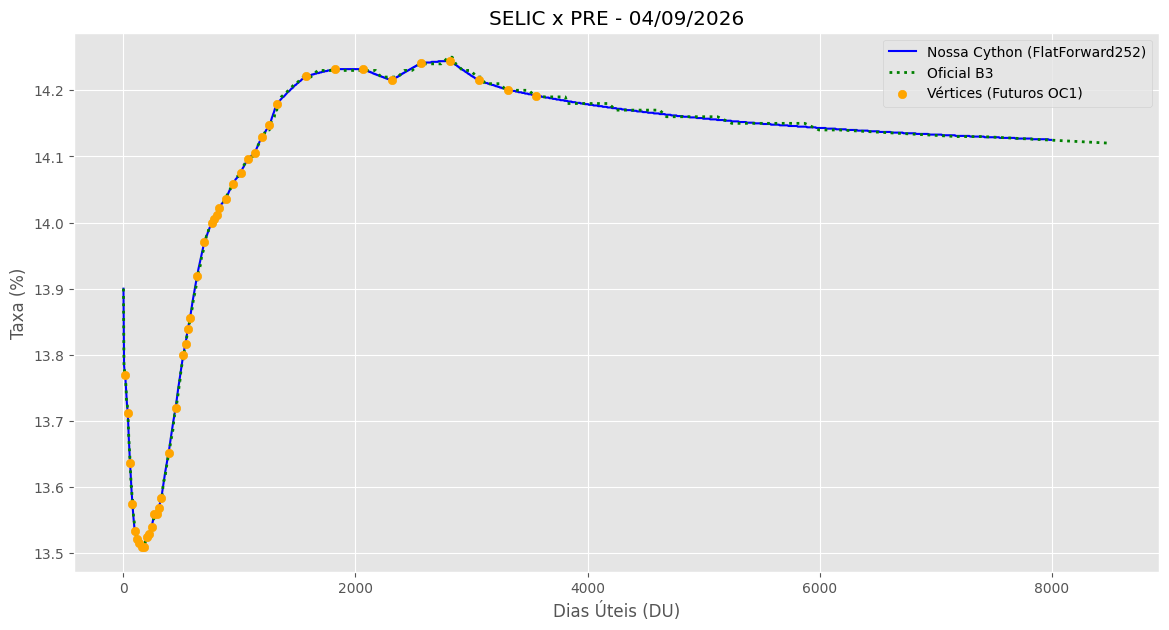

In [21]:
du_grid_selic = np.arange(1, 8000, 5)
rates_selic = [curve_selic.get_rate(float(du)) * 100 for du in du_grid_selic]

plt.plot(du_grid_selic, rates_selic, label='Nossa Cython (FlatForward252)', color='blue')

if df_b3_selic is not None and not df_b3_selic.empty:
    plt.plot(df_b3_selic['day252'], df_b3_selic['rate'], label='Oficial B3', color='green', linewidth=2, linestyle=':')

# Pontos Originais
df_oc1['DU'] = [cal.bizdays(base_date, pd.to_datetime(d).date()) for d in df_oc1['XprtnDt']]
df_oc1_valid = df_oc1[df_oc1['DU'] > 0]
plt.scatter(df_oc1_valid['DU'], df_oc1_valid['AdjstdQtTax'], color='orange', marker='o', label='Vértices (Futuros OC1)', zorder=5)

plt.title(f'SELIC x PRE - {base_date.strftime("%d/%m/%Y")}')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (%)')
plt.legend()
plt.show()

## 4. Curvas Derivativas Complexas: TBFxPRE e TRxPRE (Resolução 5.124 BCB)

In [22]:
# O tbf_pipeline já cuida de puxar o histórico da TBF e instanciar a TBFCurve
tbf_curve = build_tbf_pipeline(base_date, loader, builder)

# A partir da TBFCurve, nós envelopamos na TRCurve para aplicar a redução B3/BCB
tr_curve = builder.build_tr_curve(tbf_curve, round_decimals=4)

du_grid_tr = np.arange(1, 1500, 5)
rates_tbf = [tbf_curve.get_rate(float(du)) * 100 for du in du_grid_tr]
rates_tr = [tr_curve.get_rate(float(du)) * 100 for du in du_grid_tr]

plt.plot(du_grid_tr, rates_tbf, label='TBF x PRE (Motor Cython)', color='purple')
plt.plot(du_grid_tr, rates_tr, label='TR x PRE (Cython Res. 5.124)', color='red', linestyle='--')

plt.title(f'Curvas Derivativas: TBF e TR - {base_date.strftime("%d/%m/%Y")}')
plt.xlabel('Dias Úteis (DU)')
plt.ylabel('Taxa (%)')
plt.legend()
plt.show()

Extraindo TBF do BCB (Série 11) de 2026-08-28 a 2026-09-03...
[Erro] Falha ao processar histórico para 2026-09-03: Arquivo de cadastro não encontrado: ../dados/b3\BVBG_IN_20260903.csv
[Erro] Falha ao processar histórico para 2026-09-02: Arquivo de cadastro não encontrado: ../dados/b3\BVBG_IN_20260902.csv
[Erro] Falha ao processar histórico para 2026-09-01: Arquivo de cadastro não encontrado: ../dados/b3\BVBG_IN_20260901.csv
[Erro] Falha ao processar histórico para 2026-08-31: Arquivo de cadastro não encontrado: ../dados/b3\BVBG_IN_20260831.csv
[Erro] Falha ao processar histórico para 2026-08-28: Arquivo de cadastro não encontrado: ../dados/b3\BVBG_IN_20260828.csv


ValueError: Não foi possível calcular nenhum Fator TBF no histórico de 5 dias.